# 6. The adaptive selector in simulation (Objectives O4 and O5)

A player's true weaknesses can never be observed, so policies are compared on synthetic players whose weaknesses are known:
200 players, 150 attempts each, with real Lichess difficulty distributions. Every policy meets the same players, so
comparisons are paired.

**Sources:** `eval/research/simulation_results.json` and `eval/research/simulation_curves.json`
(`scripts/research/run_simulation.py`).

In [1]:
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

results = load('eval/research/simulation_results.json')
main = results['E2_main']
print(results['runs'], 'runs |', results['design'])

200 runs | paired by seed (common random numbers)


## Main comparison: players who do not improve

*Targeting* is the share of the last 50 puzzles from the player's three weakest categories (chance 13%). *Too hard* means a solve chance below 30%, and *well pitched* between 50% and 85%.

In [2]:
labels = {'targeting_last50': 'targeting', 'cum_regret': 'regret', 'frac_frustrating': 'too hard',
          'frac_in_zpd': 'well pitched', 'mean_p_served': 'mean solve chance'}
table = pd.DataFrame({policy: {name: row[key]['mean'] for key, name in labels.items()}
                      for policy, row in main['none']['table'].items()}).T
table.round(3)

,targeting,regret,too hard,well pitched,mean solve chance
Random,0.130,189.181,0.338,0.367,0.446
Round-robin,0.132,189.105,0.336,0.369,0.446
Static profile (top-3),0.206,166.568,0.358,0.357,0.431
Greedy (Beta mean),0.520,103.453,0.493,0.249,0.346
Beta-TS,0.404,145.876,0.441,0.291,0.383
Beta-TS (γ=0.97),0.244,164.911,0.398,0.322,0.408
IRT-TS (Elo band),0.409,142.272,0.425,0.307,0.391
IRT-TS,0.445,135.881,0.032,0.721,0.631
Oracle,1.000,0.000,0.000,0.824,0.624


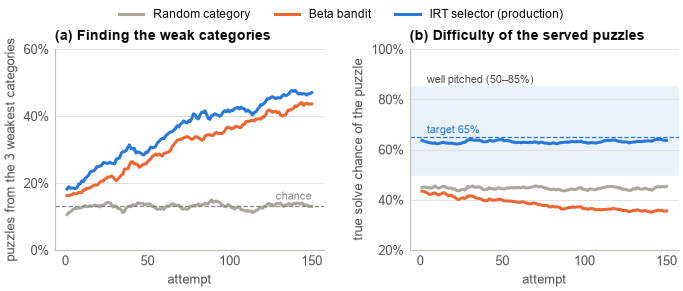

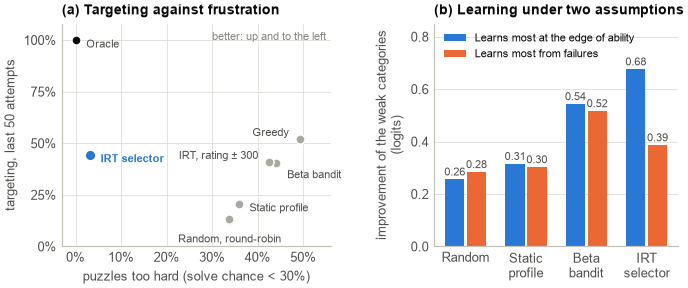

In [3]:
figures.sim_time()
figures.sim_summary()

## Does it hold when players learn?

How players learn is an assumption, so results are shown under two models. `gain_weak` is the improvement of the weak categories, on the logit scale.

In [4]:
worlds = {'none': 'no learning', 'zpd': 'learns at the edge of ability', 'error': 'learns from failures'}
pd.DataFrame({name: {policy: row['targeting_last50']['mean'] for policy, row in main[key]['table'].items()}
              for key, name in worlds.items()}).round(3)

,no learning,learns at the edge of ability,learns from failures
Random,0.130,0.130,0.131
Round-robin,0.132,0.133,0.133
Static profile (top-3),0.206,0.000,0.002
Greedy (Beta mean),0.520,0.056,0.067
Beta-TS,0.404,0.236,0.205
Beta-TS (γ=0.97),0.244,0.198,0.186
IRT-TS (Elo band),0.409,0.232,0.211
IRT-TS,0.445,0.211,0.275
Oracle,1.000,1.000,1.000


In [5]:
pd.DataFrame({worlds[key]: {policy: row['gain_weak']['mean'] for policy, row in main[key]['table'].items()}
              for key in ('zpd', 'error')}).round(3)

,learns at the edge of ability,learns from failures
Random,0.256,0.284
Round-robin,0.252,0.287
Static profile (top-3),0.315,0.302
Greedy (Beta mean),0.508,0.430
Beta-TS,0.543,0.516
Beta-TS (γ=0.97),0.429,0.436
IRT-TS (Elo band),0.563,0.539
IRT-TS,0.675,0.386
Oracle,1.238,0.884


## Criteria fixed before any result existed

These tested the original Beta bandit.

In [6]:
e1 = results['E1_preregistered']
pd.DataFrame({
    'C1 targeting, trials 131 to 150': {'result': e1['C1_targeting_trials_131_150']['mean'], 'required': 0.80, 'passed': e1['C1_targeting_trials_131_150']['pass']},
    'C2 error at trial 100': {'result': e1['C2_mae_at_trial_100']['mean'], 'required': 0.10, 'passed': e1['C2_mae_at_trial_100']['pass']},
    "C3 Cohen's d against random": {'result': e1['C3_vs_random']['cohens_d'], 'required': 0.8, 'passed': e1['C3_vs_random']['pass']},
}).T

,result,required,passed
"C1 targeting, trials 131 to 150",0.7135,0.8,False
C2 error at trial 100,0.111,0.1,False
C3 Cohen's d against random,5.382,0.8,True


## Weaknesses as small as the cohort suggests

The cohort study found little stable weakness, so the simulation was repeated with smaller effects.

In [7]:
worlds = results['E7_realistic']['worlds']
rows = {}
for world, content in worlds.items():
    for policy, row in content['table'].items():
        rows[(world, policy)] = {'targeting': row['targeting_last50']['mean'], 'too hard': row['frac_frustrating']['mean'],
                                 'well pitched': row['frac_in_zpd']['mean']}
pd.DataFrame(rows).T.round(3)

targeting  too hard  well pitched
original assumption (σ 0.35, 3 weak at −1.2) Random       0.130     0.338         0.367
                                             Beta-TS      0.422     0.452         0.280
                                             IRT-TS       0.457     0.031         0.722
                                             Oracle       1.000     0.000         0.824
subtle weaknesses (σ 0.15, 3 weak at −0.5)   Random       0.130     0.310         0.394
                                             Beta-TS      0.235     0.350         0.363
                                             IRT-TS       0.236     0.014         0.762
                                             Oracle       1.000     0.000         0.834
no category weaknesses (σ 0)                 Random       0.129     0.256         0.425
                                             Beta-TS      0.070     0.280         0.401
                                             IRT-TS       0.135     0.009         0.767
                                             Oracle       1.000     0.000         0.873

## Observations

- The production selector keeps puzzles at a true solve chance of about 63%, close to the 65% target, and cuts puzzles that
  are too hard from about a third to 3%. 72% of its puzzles are well pitched.
- The same selector with a fixed band of ±300 around the rating still serves 43% too-hard puzzles, so the low frustration
  comes from the target rating, not from how the category is chosen.
- All Thompson Sampling policies find weak categories far more often than random choice. The production selector does best among
  the policies that keep exploring (45% against 40% for the Beta bandit).
- The greedy policy targets more in this setting (52%), but it never explores: when players improve its targeting falls to 6-7%.
- When players improve, their weakest categories keep changing, so targeting falls for every policy: the production selector
  reaches 21% or 28% depending on how players learn, and the Beta bandit 24% or 21%.
- Learning gains depend on the assumption. At the edge of ability the production selector wins (0.68 against 0.54 for the Beta bandit);
  from failures the Beta bandit wins (0.52 against 0.39), because it serves more puzzles that are failed.
- The original Beta bandit passed one of the three criteria set in advance and missed the other two.
- With weaknesses as small as the cohort suggests, targeting falls to 24%, but too-hard puzzles stay at about 1%.